In [14]:
import numpy as np
from matplotlib import pyplot as plt
import json
import sys

sys.path.append("/home/hkerino/Documents/next_oso")
from pastis.pastis_dataset import PASTIS_Dataset

In [3]:
dt = PASTIS_Dataset(folder="/home/hkerino/Documents/PASTIS")

Reading patch metadata . . .
Done.
Dataset ready.


In [9]:
dt[0][1].flatten().numpy()

array([19, 19, 19, ..., 19,  0, 19], shape=(16384,))

In [20]:
def count_label(dataset, plot=True):
    classes = np.zeros(20)

    for i in range(len(dataset)):
        labels = dataset[i][1].flatten().numpy()
        if np.any(labels < 0):
            print(f"Échantillon {i} : labels contiennent des valeurs négatives !")
            print(f"Valeurs uniques : {np.unique(labels)}")
            continue  # Exclure cet échantillon

        counts = np.bincount(labels, minlength=20)
        classes += counts

    normalized_count = classes / (np.sum(classes))
    name_labels = json.load(open("/home/hkerino/Documents/PASTIS/label_names.json"))
    if plot:
        plt.figure(figsize=(12, 6))
        plt.title("Normalized labels repartition")
        plt.bar(range(normalized_count.shape[0]), normalized_count)
        plt.xticks(range(len(normalized_count)), name_labels.values(), rotation=90)
        plt.ylabel("Labels occurence")

    return normalized_count

In [17]:
name_labels = json.load(open("/home/hkerino/Documents/PASTIS/label_names.json"))

In [19]:
name_labels.values()

dict_values(['Background', 'Meadow', 'Soft winter wheat', 'Corn', 'Winter barley', 'Winter rapeseed', 'Spring barley', 'Sunflower', 'Grapevine', 'Beet', 'Winter triticale', 'Winter durum wheat', 'Fruits,  vegetables, flowers', 'Potatoes', 'Leguminous fodder', 'Soybeans', 'Orchard', 'Mixed cereal', 'Sorghum', 'Void label'])

array([0.3990614 , 0.18285751, 0.06858515, 0.08658418, 0.02034242,
       0.01769415, 0.00638932, 0.00992294, 0.0278157 , 0.00814868,
       0.00737652, 0.01053026, 0.00936432, 0.00279964, 0.01594392,
       0.01053778, 0.01033759, 0.00519376, 0.00418857, 0.09632617])

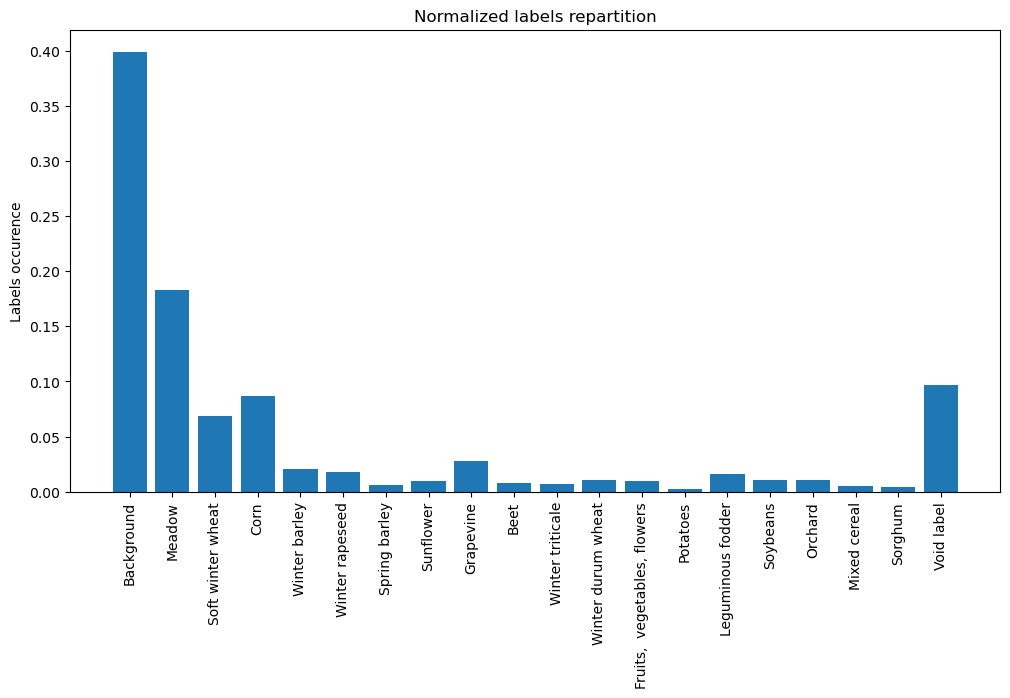

In [21]:
count_label(dt)